# GalaxyMNIST | A small convolutional-network demonstration
**Computational Astrophysics · Physics of Data**

This notebook illustrates the basic mechanics of a **single, small CNN**: RGB image tensors, PyTorch `Dataset`/`DataLoader`, one training loop, and one validation diagnostic. For clarity, we use a subset of **two** GalaxyMNIST categories rather than solving the full four-class scientific problem.

There is **no architecture search, model selection sweep, official test-set evaluation, report generator, explainability analysis, generative model, or command-line integration**. Those are outside the scope of this demonstration.

If necessary, you can run the notebook in an explicitly labelled **toy-data mode**; artificial shapes are not real galaxy data and must never be interpreted as scientific results.


## 1 — Dependencies and data

```bash
python -m pip install numpy matplotlib scikit-learn h5py torch
```

Use the [GalaxyMNIST project instructions](https://github.com/mwalmsley/galaxy_mnist) to download the official 64×64 RGB training images. This notebook can read `data/GalaxyMNIST/raw/train_dataset.hdf5` directly, or (if the package and dependencies are installed) ask the `GalaxyMNIST` loader to download its data.

PyTorch convolutions expect images ordered as `(batch, channels, height, width)`, whereas HDF5 images use `(batch, height, width, channels)`. Converting between these two orders is important.


In [1]:
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import h5py

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

USE_TOY_DATA = False       # True is strictly for offline programming demonstrations
DATA_ROOT = Path("data")
MAX_PER_CLASS = 80         # small example subset; not a scientific training choice
BATCH_SIZE = 32
EPOCHS = 2                 # quick demonstration, not convergence optimisation
CLASS_LABELS = (0, 2)
CLASS_NAMES = {0: "smooth_round", 2: "edge_on_disk"}
DEVICE = torch.device("cpu")  # portable: works even without a GPU


## 2 — Load and inspect a tiny subset

Each pixel has three channels. We select the same two categories as the classical-learning demonstration, and restrict the sample count to keep CPU execution short.


N, H, W, C: (160, 64, 64, 3) Labels: (array([0, 2]), array([80, 80]))


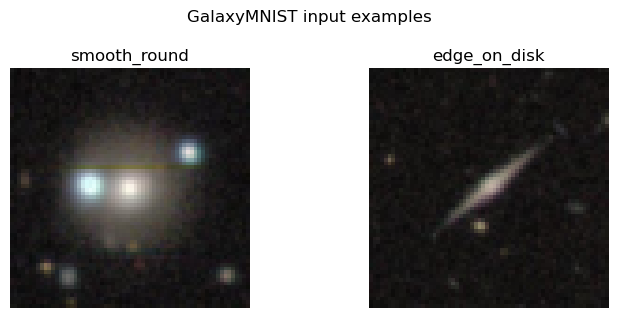

In [2]:
def toy_shapes(n_each=80, seed=42):
    """Illustrative shapes only; NOT survey observations."""
    generator = np.random.default_rng(seed)
    yy, xx = np.mgrid[-1:1:64j, -1:1:64j]
    ims, ys = [], []
    for label in CLASS_LABELS:
        for _ in range(n_each):
            size = generator.uniform(0.19, 0.39)
            if label == 0:
                intensity = np.exp(-0.5 * (xx**2 + yy**2) / size**2)
            else:
                intensity = np.exp(-0.5 * ((xx / (size*1.7))**2 + (yy/(size*0.35))**2))
            arr = np.stack([0.7 * intensity, 0.9 * intensity, 0.6 * intensity], -1)
            arr += generator.normal(0, 0.04, arr.shape)
            ims.append((np.clip(arr, 0, 1) * 255).astype(np.uint8))
            ys.append(label)
    return np.stack(ims), np.asarray(ys)


def load_examples():
    if USE_TOY_DATA:
        print("TOY MODE: artificial patterns, NOT galaxies")
        return toy_shapes(seed=SEED)
    path = DATA_ROOT / "GalaxyMNIST" / "raw" / "train_dataset.hdf5"
    if path.exists():
        with h5py.File(path, "r") as f:
            return f["images"][:], f["labels"][:].astype(int)
    try:
        from galaxy_mnist import GalaxyMNIST
        ds = GalaxyMNIST(root=str(DATA_ROOT), train=True, download=True)
        return ds.data.permute(0, 2, 3, 1).numpy(), ds.targets.numpy()
    except Exception as exc:
        raise RuntimeError(
            "Training GalaxyMNIST data are unavailable. Download the dataset as in the "
            "previous cell, or set USE_TOY_DATA=True to explore the code offline only."
        ) from exc


raw_images, raw_labels = load_examples()
assert raw_images.ndim == 4 and raw_images.shape[-1] == 3
rng = np.random.default_rng(SEED)
selected = []
for label in CLASS_LABELS:
    ids = np.flatnonzero(raw_labels == label)
    if not len(ids):
        raise ValueError(f"No observations with class label {label}")
    selected.extend(rng.choice(ids, min(MAX_PER_CLASS, len(ids)), replace=False))
selected = np.asarray(selected)
images = raw_images[selected]
labels = raw_labels[selected]
print("N, H, W, C:", images.shape, "Labels:", np.unique(labels, return_counts=True))

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
for ax, label in zip(axes, CLASS_LABELS):
    j = int(np.flatnonzero(labels == label)[0])
    ax.imshow(images[j]); ax.set_title(CLASS_NAMES[label]); ax.axis('off')
fig.suptitle("Toy patterns (not galaxy data)" if USE_TOY_DATA else "GalaxyMNIST input examples")
fig.tight_layout()
plt.show()


## 3 — Convert to channel-first tensors and split the examples

Normalise the input to `[0, 1]`. Labels for the demonstration become binary class indices `0` and `1` even though their original GalaxyMNIST indices were `0` and `2`. **Never mix the original and remapped labels by accident.**

We hold back a small validation set drawn from the official training partition. We do **not** use the official test set.


In [3]:
X_np = np.asarray(images, dtype=np.float32) / 255.0
X_tensor = torch.from_numpy(X_np).permute(0, 3, 1, 2).contiguous()
y_tensor = torch.tensor((labels == 2).astype(np.int64))

fit_indices, validation_indices = train_test_split(
    np.arange(len(y_tensor)), test_size=0.25,
    random_state=SEED, stratify=y_tensor.numpy()
)
fit_data = TensorDataset(X_tensor[fit_indices], y_tensor[fit_indices])
val_data = TensorDataset(X_tensor[validation_indices], y_tensor[validation_indices])
fit_loader = DataLoader(fit_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
print("One image tensor:", X_tensor[0].shape, "; batches:", len(fit_loader))


One image tensor: torch.Size([3, 64, 64]) ; batches: 4


## 4 — Define one small network

This example has **two** convolutional layers and a small fully connected output. `ReLU` gives the model a nonlinear response; pooling reduces spatial resolution. The final layer produces two *logits*, one per demonstration class.

`CrossEntropyLoss` expects raw logits (not softmax probabilities), so we do not add a softmax layer.


In [4]:
class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(16, 2)

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x.flatten(start_dim=1))

network = TinyCNN().to(DEVICE)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(network.parameters(), lr=0.003)
print(network)


TinyCNN(
  (features): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): AdaptiveAvgPool2d(output_size=1)
  )
  (classifier): Linear(in_features=16, out_features=2, bias=True)
)


## 5 — Fit the network for a few epochs

For each batch we clear gradients, run the network, compute loss, call `backward()`, and update the model with the optimiser. The example is intentionally short; on real galaxy data, two epochs will generally **not** be sufficient to establish a robust scientific model.


In [5]:
train_losses, validation_accuracies = [], []
for epoch in range(EPOCHS):
    network.train()
    cumulative_loss, count = 0.0, 0
    for batch_x, batch_y in fit_loader:
        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
        optimizer.zero_grad()
        logits = network(batch_x)
        loss = loss_fn(logits, batch_y)
        loss.backward()
        optimizer.step()
        cumulative_loss += float(loss.item()) * len(batch_y)
        count += len(batch_y)

    network.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            logits = network(batch_x.to(DEVICE))
            guessed = logits.argmax(1).cpu()
            correct += int((guessed == batch_y).sum())
            total += len(batch_y)
    average_loss = cumulative_loss / count
    val_accuracy = correct / total
    train_losses.append(average_loss)
    validation_accuracies.append(val_accuracy)
    print(f"Epoch {epoch+1}: training loss={average_loss:.3f}; validation accuracy={val_accuracy:.3f}")


Epoch 1: training loss=0.704; validation accuracy=0.500
Epoch 2: training loss=0.698; validation accuracy=0.500


## 6 — Interpret training and validation diagnostics

Plot the loss history and a single **validation confusion matrix**. In a binary classifier, a large total accuracy can still conceal substantial errors on one category. Here we only want to learn how to read the diagnostics, not to tune a final scientific model.


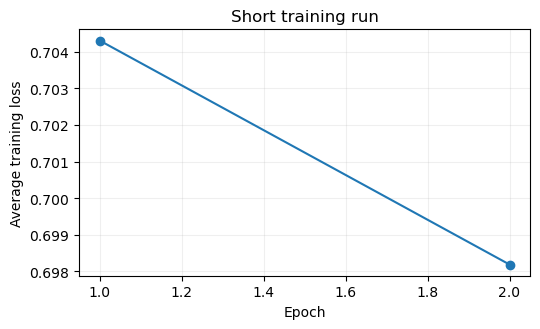

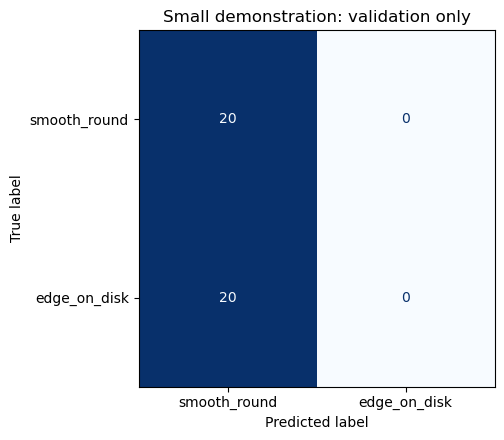

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot(np.arange(1, EPOCHS+1), train_losses, marker="o")
ax.set(xlabel="Epoch", ylabel="Average training loss", title="Short training run")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

network.eval()
true_labels, predicted_labels = [], []
with torch.no_grad():
    for xx, yy in val_loader:
        guess = network(xx.to(DEVICE)).argmax(dim=1).cpu().numpy()
        true_labels.extend(yy.numpy())
        predicted_labels.extend(guess)

cm = confusion_matrix(true_labels, predicted_labels, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[CLASS_NAMES[0], CLASS_NAMES[2]],
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Small demonstration: validation only")
fig.tight_layout()
plt.show()


## Questions to consider

- What happens to image height and width after max pooling?
- Why are tensors converted from NHWC to NCHW?
- What does the training loss describe, and what does validation accuracy describe?
- Why is evaluating the same two-class example on a held-out subset not enough to establish a general morphology classifier?
- What additional tests would be needed before publishing a model's predictive performance?

The scientific project requires students to design their own experiments and justify the results. This notebook only demonstrates **one short training run** and deliberately produces **no submission artifacts**.

**References:** [PyTorch neural-network tutorial](https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html) · [PyTorch optimisation tutorial](https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html) · [GalaxyMNIST](https://github.com/mwalmsley/galaxy_mnist).
